# Лабораторная №3. Метод Метрополиса — Хастингса для графов

Продолжение [ЛР2](lab2_interventions.ipynb): те же модели, данные,
критерий удаления и интервенция. Во второй работе каждое слагаемое
проверялось отдельно в одной фиксированной модели. Здесь графы модели
**семплируются**, а интервенция входит и в целевую функцию,
и в предложение следующего графа.

| Пункт задания | Выбор |
|---|---|
| 1. Уравнение ЛР1 | Два связанных контура; дисперсия кварцевого стекла и воды |
| 2. Критерий ЛР2 | Удалить элемент, если после переподгонки $\Delta RMSE\le\tau$ и не более 5% бутстреп-оценок лежат на границах; бутстреп, шум $\alpha s(x)\xi$, расстояние $W_1$ |
| 3. Алгоритм | Метрополис — Хастингс по графам |

## 1. Граф, параметры, данные

Модель $y=f_G(w,x)$, наблюдений $m$. Граф $G$ — набор рёбер из $K$
кандидатов, $|G|$ — число рёбер. На ребре $e$ один параметр $w_e$;
если ребра нет, параметр закреплён на значении удаления $w_e^0$ — том
же, что при проверке удаления в ЛР2 (ноль; для $R_2$ — $10^{-6}$ Ом).
Параметры модели — $w$, структурный параметр — $G$, гиперпараметры —
масштаб ошибки $s(x)$ из ЛР2, уровень интервенции $\alpha$ и вес
неустойчивости $\lambda$.

**Контуры.** $x$ — время, $y$ — ток вторичного контура $i_2=\dot q_2$.
Уравнение ЛР1 для зарядов $q=(q_1,q_2)$ со всеми видами связи контуров:

$$
\begin{bmatrix}L_1&M\\M&L_2\end{bmatrix}\ddot q
+\begin{bmatrix}R_1&R_m\\R_m&R_2\end{bmatrix}\dot q
+\begin{bmatrix}1/C_1&S_m\\S_m&1/C_2\end{bmatrix}q
=\begin{bmatrix}1\\E_2\end{bmatrix}\cos\omega x .
$$

В ЛР2 оценивались $M$ и $R_2$. Добавлены три ребра, которых в данных
нет (тот же приём, что $c_0$ в ЛР2): резистивная связь $R_m$, ёмкостная
$S_m$ и наводка источника во вторичном контуре $E_2$.

**Дисперсия.** $x$ — длина волны, $y=n^2-1$, $n$ — показатель
преломления. К резонансам Зельмейера $\varphi_j(x)=x^2/(x^2-b_j)$
добавлены полиномиальные члены:
$y=\sum_j a_j\varphi_j(x)+\sum_{p\in\{0,2,-2,-4\}}c_px^p$.
Данные — опубликованные формулы дисперсии с добавленной ошибкой,
как в ЛР2.

In [1]:
from pathlib import Path

from emlab import lab3_experiment, lab3_graphs, lab3_plots, lab3_reporting
from emlab.lab3_config import DEFAULT_CONFIG as CONFIG

ROOT = Path.cwd()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
lab3_reporting.show_environment(CONFIG)

Python 3.13.9, NumPy 2.5.4, SciPy 1.18.1


{'seed': 20261029,
 'bootstrap_replicates': 200,
 'intervention_alpha': 2.0,
 'intervention_repeats': 3,
 'stability_weight': 1.0,
 'proposal_floor': 0.1,
 'swap_probability': 0.3,
 'steps': 60000,
 'burn_in': 500,
 'exact_stability_edges': 5,
 'sequence_steps': 10,
 'stability_levels': (0.5, 1.0, 2.0, 4.0),
 'weight_grid': (0.0, 0.5, 1.0, 2.0, 4.0),
 'notebook_timeout_seconds': 7200}

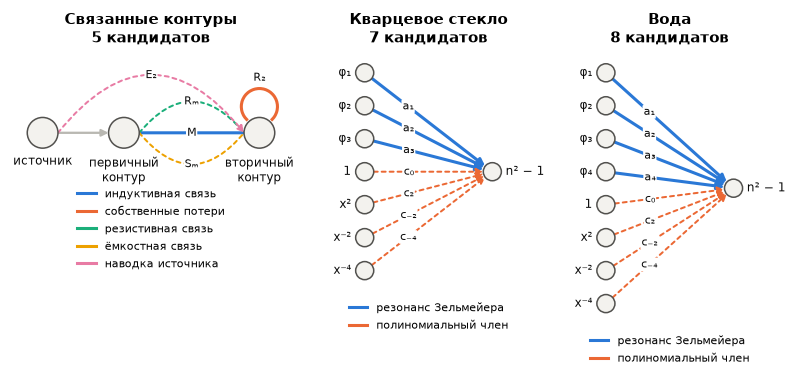

|Задача|Ребро|Вершины|Смысл|Параметр|Значение без ребра|Границы|В порождающей модели|
|---|---|---|---|---|---|---|---|
|Связанные контуры|M|первичный контур → вторичный контур|индуктивная связь|`M [nH]`|0|[0.1; 100]|да|
|Связанные контуры|R₂|вторичный контур → вторичный контур|собственные потери|`R2 [ohm]`|1e-06|[0.5; 15]|да|
|Связанные контуры|Rₘ|первичный контур → вторичный контур|резистивная связь|`Rm [ohm]`|0|[-1; 1]|нет|
|Связанные контуры|Sₘ|первичный контур → вторичный контур|ёмкостная связь|`Sm [1/uF]`|0|[-200; 200]|нет|
|Связанные контуры|E₂|источник → вторичный контур|наводка источника|`E2 [mV]`|0|[-500; 500]|нет|
|Кварцевое стекло|a₁|φ₁ → n² − 1|резонанс Зельмейера|`a1`|0|[0; 3]|да|
|Кварцевое стекло|a₂|φ₂ → n² − 1|резонанс Зельмейера|`a2`|0|[0; 3]|да|
|Кварцевое стекло|a₃|φ₃ → n² − 1|резонанс Зельмейера|`a3`|0|[0; 3]|да|
|Кварцевое стекло|c₀|1 → n² − 1|полиномиальный член|`c0`|0|[-0.1; 0.1]|нет|
|Кварцевое стекло|c₂|x² → n² − 1|полиномиальный член|`c2`|0|[-0.1; 0.1]|нет|
|Кварцевое стекло|c₋₂|x⁻² → n² − 1|полиномиальный член|`c-2`|0|[-0.1; 0.1]|нет|
|Кварцевое стекло|c₋₄|x⁻⁴ → n² − 1|полиномиальный член|`c-4`|0|[-0.1; 0.1]|нет|
|Вода|a₁|φ₁ → n² − 1|резонанс Зельмейера|`a1`|0|[0; 3]|да|
|Вода|a₂|φ₂ → n² − 1|резонанс Зельмейера|`a2`|0|[0; 3]|да|
|Вода|a₃|φ₃ → n² − 1|резонанс Зельмейера|`a3`|0|[0; 3]|да|
|Вода|a₄|φ₄ → n² − 1|резонанс Зельмейера|`a4`|0|[0; 3]|да|
|Вода|c₀|1 → n² − 1|полиномиальный член|`c0`|0|[-0.1; 0.1]|нет|
|Вода|c₂|x² → n² − 1|полиномиальный член|`c2`|0|[-0.1; 0.1]|нет|
|Вода|c₋₂|x⁻² → n² − 1|полиномиальный член|`c-2`|0|[-0.1; 0.1]|нет|
|Вода|c₋₄|x⁻⁴ → n² − 1|полиномиальный член|`c-4`|0|[-0.1; 0.1]|нет|

In [2]:
problems = lab3_graphs.prepare_problems(ROOT)
lab3_plots.plot_candidates(ROOT, problems)
lab3_reporting.show_edges(problems)

Сплошные рёбра порождали данные, пунктирные — нет. Связи контуров
взаимные, поэтому их граф не ациклический: ациклической была бы его
развёртка по времени. Графы дисперсии ациклические.

## 2. Целевая функция

**Первый уровень, граф фиксирован.** Параметры имеющихся рёбер
оцениваются взвешенным методом наименьших квадратов с границами
на параметры:
$\chi^2(G)=\min_w\bigl\|(y-f_G(w,x))/s(x)\bigr\|^2$,
$\hat w$ — точка минимума.

**Второй уровень, выбор графа.** Графы семплируются из распределения
$\pi(G)\propto\exp(-J(G))$,

$$
J(G)=\underbrace{\tfrac12\chi^2(G)}_{\text{невязка}}
+\tfrac12\ln m\,\Bigl(\underbrace{|G|}_{\text{сложность}}
+\lambda\underbrace{\sum_{e\in G}u_e(G)}_{\text{неустойчивость к интервенции}}\Bigr).
$$

Первые два слагаемых — приближение Шварца для $-\ln p(y\mid G)$
с точностью до константы и $O(1)$ при известном $s(x)$ и параметрах
внутри границ. Третье — регуляризатор по интервенции,
$u_e\in[0,1]$ — неустойчивость ребра. Он вычисляется по тем же данным,
поэтому $\pi$ — распределение Гиббса, а не апостериорное $p(G\mid y)$.

**Устойчивость ребра.** Интервенция — шум в отклике:
$y'=y+\alpha s(x)\xi$, $\xi\sim N(0,1)$. $P_e$ и $P'_e$ —
бутстреп-распределения $w_e$ до и после интервенции (обе процедуры
из ЛР2), $\delta_{w_e^0}$ — распределение, сосредоточенное в значении
удаления:

$$
\rho_e=\frac{\overline{W_1(P_e,P'_e)}}{W_1(P_e,\delta_{w_e^0})},
\qquad u_e=\min(1,\rho_e),
$$

черта — среднее по 3 реализациям $\xi$. Числитель — расстояние
из ЛР2, сдвиг параметра при интервенции. Знаменатель равен среднему
$|w_e-w_e^0|$ по $P_e$ — это сдвиг при удалении ребра.
Порог $\rho_e=1$: интервенция сдвигает параметр не меньше, чем удаление
ребра. Если параметр не определён данными (не меняется при бутстрепе
или более 5% оценок лежат на границе до или после интервенции — порог
ЛР2), то $u_e=1$.

В модели кварцевого стекла с $c_0$ нормировка ЛР2 на стандартное отклонение
$\sigma_e$ распределения $P_e$ не отделяет лишний параметр
от порождающих: при $\alpha=2$ отношение $W_1(P_e,P'_e)/\sigma_e$
равно 1.7–2.5 для всех четырёх параметров.

**Порог отклонения ребра.** $\Delta J_e$ — изменение $J$ при смене
состояния ребра $e$: удалении, если оно есть, и добавлении, если нет.
При удалении
$\Delta J_e\approx\tfrac12\bigl(\Delta\chi^2_e-(1+\lambda u_e)\ln m\bigr)$,
где $\Delta\chi^2_e$ — изменение $\chi^2$ (изменение $u$ остальных рёбер
не учтено). Удаление выгодно, если
$\Delta\chi^2_e\le(1+\lambda u_e)\ln m$: без интервенции порог равен
$\ln m$, для неустойчивого ребра он выше в $1+\lambda$ раз. Правило ЛР2
решает тот же вопрос по $\Delta RMSE$ на отложенной сетке, один раз
и детерминированно.

**Что измеряет критерий.** Для хорошо определённого параметра
$\rho_e\approx\kappa/|z_e|$, где $z_e=(\hat w_e-w_e^0)/\sigma_e$ —
статистика Вальда, а $\kappa=W_1(P_e,P'_e)/\sigma_e$ зависит от $\alpha$
и реализации шума. Шум в отклике показывает, насколько прочно ребро
определено данными, а не направление связи, и в линейном приближении
не даёт информации сверх $\Delta\chi^2_e$: регуляризатор усиливает
штраф за слабо определённые рёбра. Правила do-исчисления — условия
на граф; вопрос правила 3 (можно ли игнорировать интервенцию) здесь
решается только эмпирически, по сдвигу оценки.

## 3. Алгоритм

Источник: Метрополис и др. (1953), Хастингс (1970); для графов —
structure MCMC: добавление и удаление ребра (Madigan, York, 1995),
обращение ребра (Giudici, Castelo, 2003).

| | Structure MCMC | В работе |
|---|---|---|
| Состояние | ациклический граф | набор рёбер из $K$ кандидатов |
| Ходы | добавить, удалить, обратить ребро | добавить, удалить, заменить ребро другим |
| Цель | $p(G\mid y)$ | $\exp(-J(G))$: невязка, сложность, неустойчивость |
| Предложение | равномерное | удаление — по интервенции на текущем графе |
| Результат | вероятности рёбер | сохранённые графы цепей и $G^*=\arg\min J$ по ним |

1. $G_0$ — полный, пустой или случайный граф; $t$ — номер шага.
2. Для $G_t$: подгонка $\hat w$, бутстреп, интервенция, бутстреп;
   получаем $u_e(G_t)$ и $J(G_t)$.
3. Предложить $G'$ из распределения $Q(G'\mid G_t)$. С вероятностью
   $1-p_s$ сменить состояние одного ребра, выбранного с весом
   $v_e=\varepsilon+u_e(G_t)$, если ребро есть, и $v_e=1$, если его нет:
   неустойчивые рёбра чаще предлагаются к удалению. С вероятностью $p_s$
   заменить случайное имеющееся ребро случайным отсутствующим.
4. Повторить шаг 2 для $G'$.
5. Принять $G_{t+1}=G'$ с вероятностью
   $A(G_t,G')=\min\Bigl\{1,\;\exp\bigl(J(G_t)-J(G')\bigr)\,\dfrac{Q(G_t\mid G')}{Q(G'\mid G_t)}\Bigr\}$,
   иначе $G_{t+1}=G_t$.
6. Сохранить $G_{t+1}$ и перейти к шагу 2.

Два этапа. **Без интервенции**: $\lambda=0$, $v_e\equiv1$.
**С интервенцией**: $\lambda=1$, $\varepsilon=0.1$,
$\alpha=2$. На обоих $p_s=0.3$.
$G^*=\arg\min J$ берётся по всем сохранённым графам, частоты —
без первых 500 шагов (прогрев).

**Корректность.** При любом $G_0$ распределение $G_t$ сходится к $\pi$,
а частоты графов в цепи — к $\pi(G)$.

- *Обратимость.*
  $\pi(G)Q(G'\mid G)A(G,G')=\min\{\pi(G)Q(G'\mid G),\,\pi(G')Q(G\mid G')\}$
  симметрично по $G,G'$, значит $\pi$ стационарно. Смена одного ребра
  меняет $|G|$, замена — нет, поэтому каждый сосед получается ровно
  одним ходом и $Q$ — полная вероятность предложения.
- *Неприводимость.* $v_e\ge\varepsilon>0$ и $J$ конечна, поэтому
  любая смена одного ребра возможна; между любыми двумя графами
  не более $K$ таких ходов.
- *Апериодичность.* В пустом и полном графе замена невозможна, и цепь
  остаётся на месте с вероятностью $p_s>0$.

Конечная неприводимая апериодическая цепь сходится к единственному
стационарному распределению. Условие: $J$ и $v_e$ — функции только
графа. Поэтому индексы бутстрепа и шум интервенции $\xi$ общие для всех
графов, а результаты кешируются.

Реализация проверена тестами на случайно заданном распределении
по 16 графам с неравномерными весами: переходы цепи совпадают с точной
матрицей переходов, частоты сходятся к $\pi$.

## 4. Эксперимент

На каждом этапе три цепи по 60000 шагов. Полным перебором $\pi$
вычислено без интервенции для всех задач, с интервенцией — для контуров
(32 графа). Все графы цепей сохраняются в `results/lab3/chains.npz`.

In [3]:
results = {
    name: lab3_experiment.run_problem(problem, CONFIG)
    for name, problem in problems.items()
}
summary = lab3_experiment.save_results(ROOT, results)

rlc: 5 edges, 32 graphs


silica: 7 edges, 128 graphs


water: 8 edges, 256 graphs


### 4.1. Правило ЛР2 на полном графе

Применяем правило удаления ЛР2 к графу со всеми пятью рёбрами.

In [4]:
rlc = results["rlc"]
lab3_reporting.show_lab2_rule(rlc, (True,) * len(rlc.problem.edges))

Связанные контуры, граф {M, R₂, Rₘ, Sₘ, E₂}: доля бутстреп-оценок на границах 72%


|Ребро|Оценка|ΔRMSE|Допуск τ|Параметр определён|Неустойчивость uₑ|Правило ЛР2|
|---|---|---|---|---|---|---|
|M|31.37|-6.46e-08|0.00162|нет|1|СОХРАНИТЬ|
|R₂|4.072|0.00355|0.00162|да|0.017|СОХРАНИТЬ|
|Rₘ|0.05877|-1.26e-07|0.00162|да|0.069|СОХРАНИТЬ|
|Sₘ|200|-6.3e-08|0.00162|нет|1|СОХРАНИТЬ|
|E₂|28.16|-9.09e-08|0.00162|да|0.045|СОХРАНИТЬ|

По $\Delta RMSE\le\tau$ удалимы $M$, $R_m$, $S_m$ и $E_2$: каждое
по отдельности заменимо остальными, включая порождающее $M$ — его
компенсирует $S_m$. Проверка границ при этом запрещает все удаления.
Проверка рёбер по одному в полном графе не приводит к $\{M,R_2\}$,
поэтому перебираем графы.

### 4.2. Устойчивость рёбер к интервенции

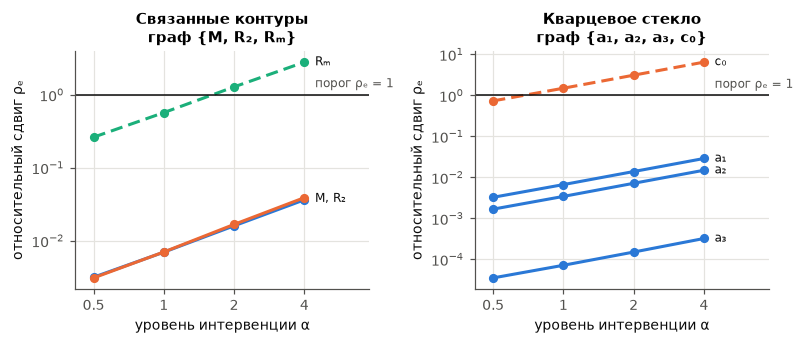

In [5]:
lab3_plots.plot_stability(
    ROOT, lab3_experiment.stability_cases(results), CONFIG.stability_levels
)

Графы — порождающие рёбра плюс одно лишнее. Порождающие рёбра
(сплошные линии) остаются более чем на порядок ниже порога при всех
показанных $\alpha$. Лишнее ребро (пунктир) пересекает порог при $\alpha$ между
1 и 2 для контуров и между 0.5 и 1 для кварцевого стекла. Далее $\alpha=2$,
как в примере ЛР2. Пересечение зависит от реализации шума: у $c_2$
в обеих задачах дисперсии $\rho_e$ чуть ниже 1 (таблица в 4.5),
штраф $u_e$ при этом почти полный.

### 4.3. Последовательность семплированных графов

С интервенцией, старт из полного графа. Показаны принятые графы
и $J(G_t)-J(G^*)$; между показанными шагами все предложения
отклонены. Узлы слева направо: источник, первичный контур,
вторичный контур.

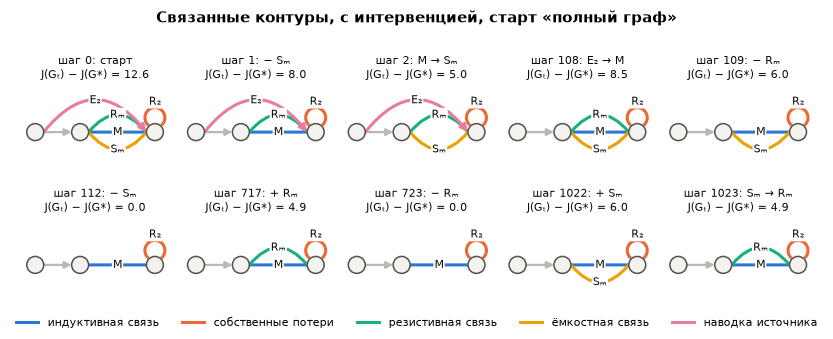

In [6]:
lab3_plots.plot_sequence(
    ROOT,
    rlc,
    lab3_experiment.INTERVENTIONAL,
    "полный граф",
    CONFIG.sequence_steps,
)

Цепь сначала попадает в граф без $M$: ёмкостная связь с поправками
$R_m$ и $E_2$ описывает ток почти так же. Выходит она оттуда заменой
ребра на $M$, после чего лишние рёбра удаляются. Дальше цепь остаётся
в $\{M,R_2\}$ и изредка принимает одно лишнее ребро.

### 4.4. Сходимость и проверка корректности

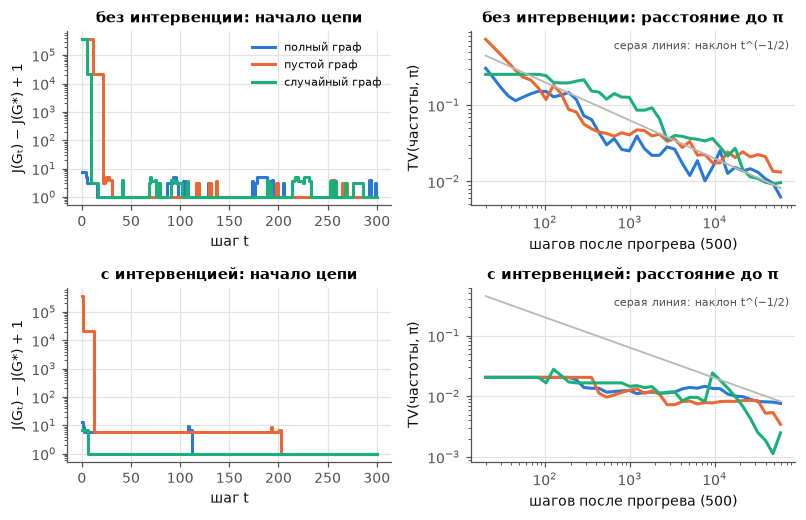

|Предложение|Ошибка детального баланса|Шагов до G* из полного графа|Шагов до G* из пустого графа|Спектральный зазор|Доля принятых шагов|
|---|---|---|---|---|---|
|равномерное|2.7e-20|102|73|4.77e-03|0.0050|
|по интервенции|1.1e-19|113|70|5.14e-03|0.0075|

In [7]:
lab3_plots.plot_convergence(ROOT, rlc)
lab3_reporting.show_proposals(rlc)

Слева — целевая функция в начале цепи: все три старта приходят
к одному минимуму. Справа — расстояние полной вариации (TV) между
частотами графов в цепи и точным $\pi$. Без интервенции оно убывает
примерно как $t^{-1/2}$ (серая линия). С интервенцией почти вся масса
$\pi$ лежит в одном графе,
поэтому малое расстояние не говорит о точности частот редких графов;
в 4.5 частоты рёбер сравниваются с точными.

Таблица посчитана по точной матрице переходов с интервенцией.
Детальный баланс следует из построения; строка проверяет реализацию
$Q$. Предложение
по интервенции принимается в полтора раза чаще, спектральный зазор
немного больше. Из полного графа оно идёт к $G^*$ дольше: там $M$
не определён данными ($u_e=1$) и чаще предлагается к удалению.

### 4.5. Выбор графа

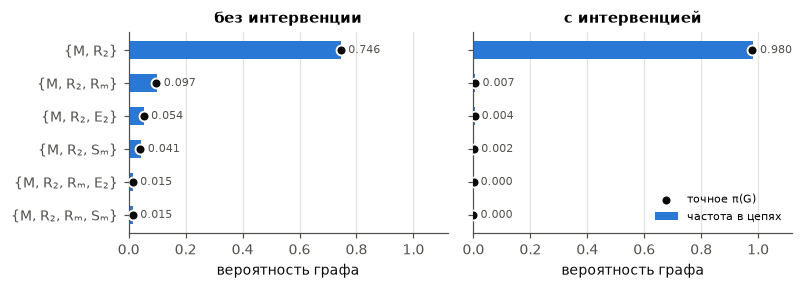

|Задача|Этап|Выбранный граф G*|Совпал с порождающим|Частота G* в цепях|Точное π(G*)|Доля принятых шагов|max TV по цепям|Правило ЛР2 согласно с итогом|
|---|---|---|---|---|---|---|---|---|
|Связанные контуры|без интервенции|{M, R₂}|да|0.746|0.746|0.109|0.013|да|
|Связанные контуры|с интервенцией|{M, R₂}|да|0.982|0.980|0.008|0.008|да|
|Кварцевое стекло|без интервенции|{a₁, a₂, a₃}|да|0.676|0.671|0.103|0.018|да|
|Кварцевое стекло|с интервенцией|{a₁, a₂, a₃}|да|0.968|—|0.013|—|да|
|Вода|без интервенции|{a₁, a₂, a₃, a₄}|да|0.505|0.512|0.127|0.018|да|
|Вода|с интервенцией|{a₁, a₂, a₃, a₄}|да|0.942|—|0.023|—|да|

In [8]:
lab3_plots.plot_posterior(ROOT, rlc)
lab3_reporting.show_summary(results)

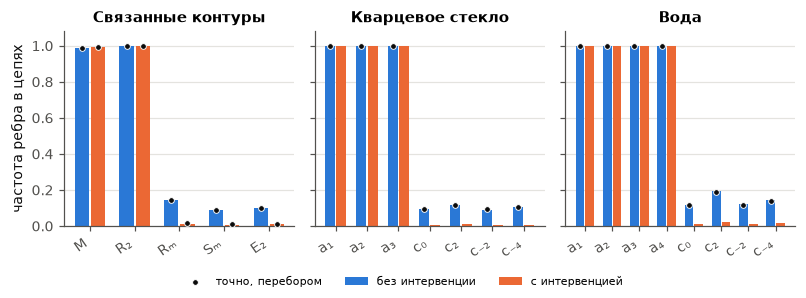

|Задача|Ребро|В G*|ρₑ|uₑ|ΔJₑ без интервенции|ΔJₑ с интервенцией|Частота с интервенцией|Точная частота|ΔRMSE / τ|Правило ЛР2|
|---|---|---|---|---|---|---|---|---|---|---|
|Связанные контуры|M|да|0.0158|0.016|3.6e+05|3.6e+05|0.9951|0.9933|9.2|СОХРАНИТЬ|
|Связанные контуры|R₂|да|0.0166|0.017|2.12e+04|2.12e+04|1.0000|1.0000|2.2|СОХРАНИТЬ|
|Связанные контуры|Rₘ|нет|1.28|1|2.04|4.95|0.0124|0.0142|-0.0052|УДАЛИТЬ|
|Связанные контуры|Sₘ|нет|1.7|1|2.9|6.01|0.0072|0.0093|-4.6e-05|УДАЛИТЬ|
|Связанные контуры|E₂|нет|1.67|1|2.63|5.53|0.0092|0.0109|-0.0018|УДАЛИТЬ|
|Кварцевое стекло|a₁|да|0.000313|0.00031|4.05e+07|4.05e+07|1.0000|—|91|СОХРАНИТЬ|
|Кварцевое стекло|a₂|да|0.000528|0.00053|1.49e+07|1.49e+07|1.0000|—|55|СОХРАНИТЬ|
|Кварцевое стекло|a₃|да|0.000173|0.00017|8.58e+07|8.58e+07|1.0000|—|1.8e+02|СОХРАНИТЬ|
|Кварцевое стекло|c₀|нет|3.12|1|2.53|5.12|0.0060|—|-1.7e-05|УДАЛИТЬ|
|Кварцевое стекло|c₂|нет|0.872|0.87|2.02|4.23|0.0133|—|-0.0052|УДАЛИТЬ|
|Кварцевое стекло|c₋₂|нет|3.08|1|2.53|5.09|0.0061|—|-3.5e-05|УДАЛИТЬ|
|Кварцевое стекло|c₋₄|нет|2.8|1|2.49|5.04|0.0071|—|-0.00025|УДАЛИТЬ|
|Вода|a₁|да|0.000444|0.00044|3.5e+08|3.5e+08|1.0000|—|3e+02|СОХРАНИТЬ|
|Вода|a₂|да|0.00238|0.0024|4.58e+05|4.58e+05|1.0000|—|11|СОХРАНИТЬ|
|Вода|a₃|да|0.00833|0.0083|3.88e+04|3.88e+04|1.0000|—|3.2|СОХРАНИТЬ|
|Вода|a₄|да|0.00152|0.0015|6.1e+05|6.1e+05|1.0000|—|15|СОХРАНИТЬ|
|Вода|c₀|нет|2.02|1|1.89|4.58|0.0094|—|-0.0061|УДАЛИТЬ|
|Вода|c₂|нет|0.94|0.94|1.22|3.72|0.0216|—|-0.012|УДАЛИТЬ|
|Вода|c₋₂|нет|1.93|1|1.85|4.5|0.0115|—|-0.0063|УДАЛИТЬ|
|Вода|c₋₄|нет|1.35|1|1.61|4.16|0.0156|—|-0.0077|УДАЛИТЬ|

|Вес неустойчивости λ|0|0.5|1|2|4|
|---|---|---|---|---|---|
|π({M, R₂})|0.7461|0.9295|0.9795|0.9969|0.9997|

In [9]:
lab3_plots.plot_edge_frequencies(ROOT, results)
lab3_reporting.show_edge_report(results)
lab3_reporting.show_weight_sensitivity(rlc)

На обоих этапах и во всех задачах $G^*$ — граф, породивший данные.
В таблице $\Delta J_e$ — изменение $J$ при смене состояния ребра
в $G^*$. Каждое лишнее ребро проигрывает уже без интервенции
($\Delta J_e>0$), поэтому регуляризатор выбор не меняет.
Он умножает вес графа с лишним ребром
на $m^{-\lambda u_e/2}\approx m^{-\lambda/2}$: частота лишних рёбер
падает примерно на порядок, частота $G^*$ растёт.

Точки на рисунке и столбец «Точная частота» получены перебором; цепи
с ними согласны. Правило ЛР2, применённое к $G^*$ (для отсутствующего
ребра — к $G^*$ с этим ребром), согласно с выбором.

### 4.6. Выборка и аппроксимация выбранным графом

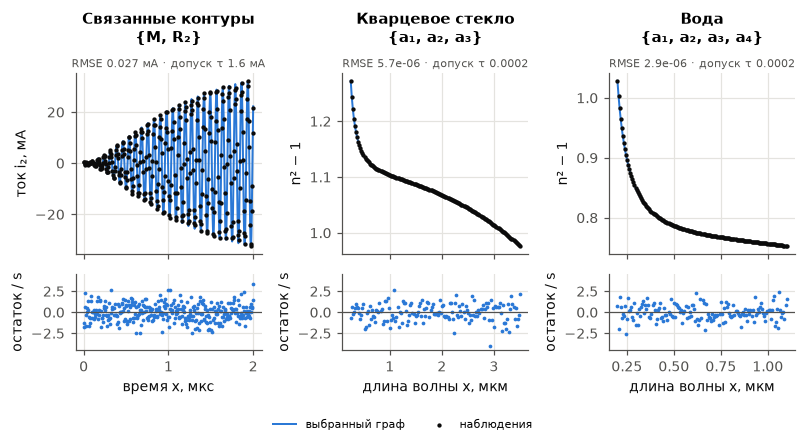

In [10]:
lab3_plots.plot_approximation(ROOT, results)

Точки — наблюдения, линия — модель выбранного графа, внизу остатки
в единицах $s(x)$. Ошибка на отложенной сетке ЛР2 более чем на порядок
меньше допуска $\tau$.

## Источники

- Metropolis N. и др. (1953). Equation of State Calculations by Fast
  Computing Machines. https://doi.org/10.1063/1.1699114
- Hastings W. K. (1970). Monte Carlo Sampling Methods Using Markov Chains
  and Their Applications. https://doi.org/10.1093/biomet/57.1.97
- Madigan D., York J. (1995). Bayesian Graphical Models for Discrete Data.
  https://doi.org/10.2307/1403615
- Giudici P., Castelo R. (2003). Improving Markov Chain Monte Carlo Model
  Search for Data Mining. https://doi.org/10.1023/A:1020202028934
- Schwarz G. (1978). Estimating the Dimension of a Model.
  https://doi.org/10.1214/aos/1176344136
- Стрижов В. В. Прикладной регрессионный анализ, части 1 и 4;
  Diffusion of linear operators: the algorithm (2026).
  https://github.com/vadim-vic/causal-Inference
- Heiss A. (2021). Do-calculus adventures! Exploring the three rules
  of do-calculus.
  https://www.andrewheiss.com/blog/2021/09/07/do-calculus-backdoors/
- ЛР2: https://github.com/TeoSable/fda_lab2,
  ЛР1: https://github.com/KasiukVadim/iad_fall_2026
- Данные: Malitson (1965) https://doi.org/10.1364/JOSA.55.001205,
  Daimon, Masumura (2007) https://doi.org/10.1364/AO.46.003811;
  HTTP-адреса — в `data/provenance.json`.

Описание эксперимента и запуск — `docs/LAB3_GUIDE.md`.